<a href="https://colab.research.google.com/github/Carmen10-171/04MIAR_Aprendizaje-Supervisado-practicas/blob/main/Laboratorio_OCT_Glaucoma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio OCT: versión adaptable a SYN-OCT

**Cuaderno comentado para JupyterLab.** Reconstruido de las capturas del archivo Word (32 páginas). Cada celda corresponde a una etapa del profesor. Se usa el mismo código probado que los archivos de `scripts/`. **No es una herramienta diagnóstica.**

## Antes de empezar: preparar SYN-OCT

1. Descarga `SYN-OCT.zip` (3.3 GB) de https://zenodo.org/records/17151869 (no incluido).
2. **No lo descomprimas**. En PowerShell, desde la carpeta del proyecto, ejecuta:
   `python PREPARAR_SYN_OCT.py --zip "C:/Users/ccope/Downloads/SYN-OCT.zip"`
3. Verifica `Material/ADVERTENCIA_SEGMENTACION.txt`: **Retina_masks es una ROI proxy generada, NO una máscara de retina clínica**.
4. Ejecuta las celdas de este notebook de arriba abajo.

Puedes usar antes `00_Preparacion_SYN_OCT.ipynb` como asistente de preparación. El material contiene imágenes OCT **sintéticas** y no reproducirá exactamente las métricas del profesor.


In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Encontramos la raíz del proyecto independientemente de si Jupyter se abrió
# desde la carpeta principal o desde /notebooks.
ROOT = Path.cwd().resolve()
if not (ROOT / "pipeline_oct.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "pipeline_oct.py").is_file():
    raise FileNotFoundError("Abre JupyterLab desde la carpeta del proyecto.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline_oct import (project_paths, read_metadata, read_triplet,
    explore, split_data, extract_one, extract_dataset, FEATURE_NAMES,
    prepare_final_features, train_models, evaluate)

# CAMBIAR A True SOLO si quieres comprobar las operaciones con imágenes sintéticas.
MODO_DEMO = False
if MODO_DEMO:
    from PRUEBA_SINTETICA import create_demo_dataset
    DATA_ROOT = ROOT / "demo_jupyter"
    create_demo_dataset(DATA_ROOT)
    print("MODO DEMOSTRACIÓN: los casos son inventados, NO son datos médicos")
else:
    DATA_ROOT = ROOT
print("Dataset utilizado:", DATA_ROOT)
p = project_paths(DATA_ROOT)

Dataset utilizado: C:\Users\ccope\MIAR\01MIAR_ABR26\Documentacion\Aprendizaje Supervisado\Video-LIV


## 1. Explorar el dataset y ver las máscaras

La columna **ID** identifica un archivo de imagen; la columna **Class** es la etiqueta supervisada. En las primeras capturas del profesor aparecen 189 registros. La función revisa esos nombres, cuenta las clases y genera una imagen tripartita.

Total de imágenes en la tabla: 189
Distribución de clases: {'healthy': 96, 'glaucoma': 93}


,ID,Class
0,SYNOCT_S_0070.png,healthy
1,SYNOCT_G_0079.png,glaucoma
2,SYNOCT_G_0070.png,glaucoma
3,SYNOCT_G_0013.png,glaucoma
4,SYNOCT_G_0034.png,glaucoma


,n_casos
Class,
healthy,96
glaucoma,93


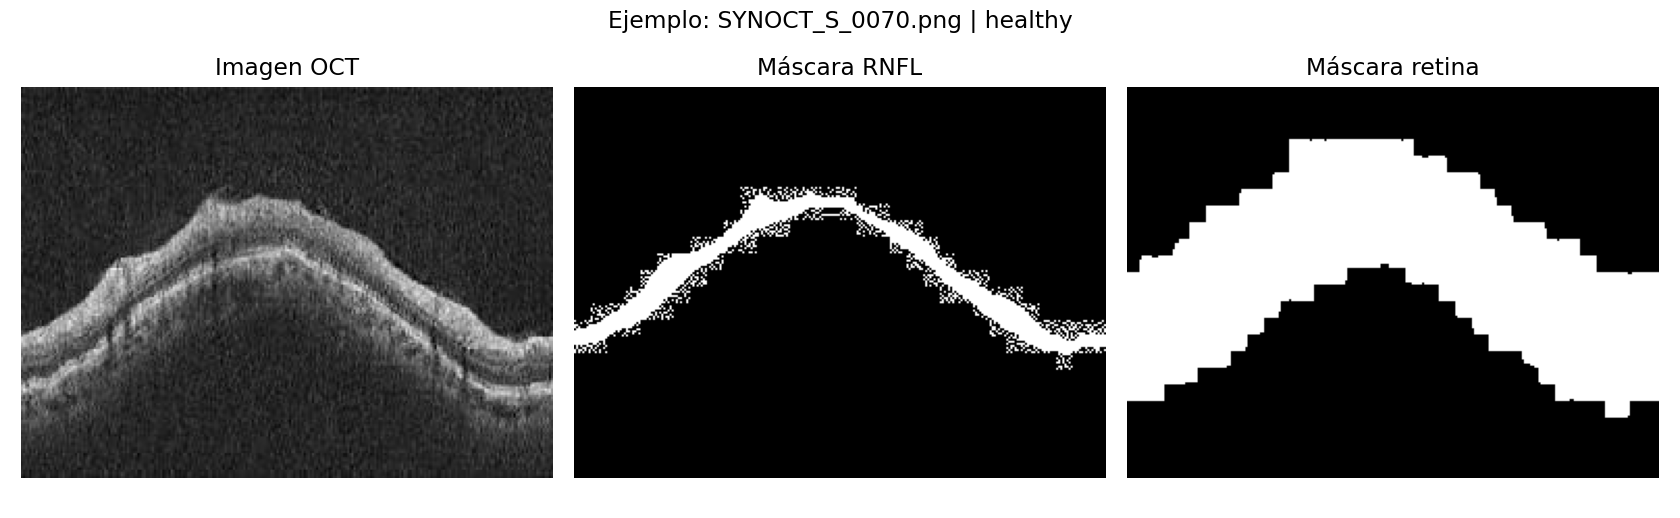

In [ ]:
df = explore(DATA_ROOT)
display(df.head())
display(df["Class"].value_counts().rename("n_casos").to_frame())
display(Image(filename=str(p["reports"] / "01_visualizacion_mascaras.png")))

### Entender una imagen como matrices

Una OCT en escala de grises es una matriz `alto × ancho`. Sus dos máscaras son otras dos matrices de igual tamaño; los píxeles no nulos identifican las zonas segmentadas. Este paso reproduce la superposición de contornos que muestra el profesor.

In [ ]:
image, rnfl_mask, retina_mask = read_triplet(p, df.iloc[0]["ID"])
print("OCT:", image.shape, image.dtype)
print("RNFL:", rnfl_mask.shape, "| píxeles con máscara:", int((rnfl_mask>0).sum()))
print("Retina:", retina_mask.shape, "| píxeles con máscara:", int((retina_mask>0).sum()))

OCT: (188, 256) uint8
RNFL: (188, 256) | píxeles con máscara: 3647
Retina: (188, 256) | píxeles con máscara: 17606


## 2. Partición externa o hold-out

Separamos 80% para aprender y 20% para el **examen final**, conservando la proporción de clases mediante `stratify`. La semilla 42 hace reproducible la selección. No permitiremos que la prueba influya en los parámetros de la selección ni del escalador.

In [ ]:
train, test = split_data(DATA_ROOT)
print("Entrenamiento: ", train.shape)
print("Prueba: ", test.shape)
display(train.head())

Entrenamiento: 151 {'healthy': 77, 'glaucoma': 74}
Prueba: 38 {'healthy': 19, 'glaucoma': 19}
Entrenamiento:  (151, 2)
Prueba:  (38, 2)


,ID,Class
0,SYNOCT_S_0005.png,healthy
1,SYNOCT_G_0076.png,glaucoma
2,SYNOCT_S_0067.png,healthy
3,SYNOCT_G_0007.png,glaucoma
4,SYNOCT_S_0004.png,healthy


## 3. Extracción de características de imagen

**7 RNFL**: media, mediana, desviación, asimetría, curtosis, mínimo y máximo del espesor por columna. **6 GLCM**: textura del recorte de la retina. **10 LBP**: frecuencias normalizadas de patrones locales. **Total = 23** números para cada OCT.

In [ ]:
vector = extract_one(image, rnfl_mask, retina_mask)
print("Longitud del vector:", len(vector))
display(pd.DataFrame({"caracteristica": FEATURE_NAMES, "valor": vector}))

Longitud del vector: 23


,caracteristica,valor
0,media,18.648438
1,mediana,18.000000
2,std,5.498707
3,asim,0.535614
4,curtosis,-0.474720
5,min,9.000000
6,max,32.000000
7,contraste,624.014885
8,disimilitud,16.273171
9,homogeneidad,0.081803


### Extraer todas las imágenes

Convertimos ambos CSV en matrices; cada fila es una OCT y cada columna un atributo. Se agrega `0=healthy`, `1=Glaucoma` como **columna 24**, igual que la idea de la diapositiva `(152,24)`.

In [ ]:
X_train, y_train = extract_dataset(DATA_ROOT, "train")
X_test, y_test = extract_dataset(DATA_ROOT, "test")
print("Matriz train (X):", X_train.shape, "  etiquetas:", y_train.shape)
print("Matriz test (X):", X_test.shape, "  etiquetas:", y_test.shape)
display(pd.DataFrame(X_train[:5], columns=FEATURE_NAMES))

Características train: X=(151, 23); y=(151,)
Características test: X=(38, 23); y=(38,)
Matriz train (X): (151, 23)   etiquetas: (151,)
Matriz test (X): (38, 23)   etiquetas: (38,)


,media,mediana,std,asim,curtosis,min,max,contraste,disimilitud,homogeneidad,...,LBP1,LBP2,LBP3,LBP4,LBP5,LBP6,LBP7,LBP8,LBP9,LBP10
0,17.039062,16.0,4.753950,-0.165210,-0.992619,5.0,24.0,854.849057,19.820864,0.072041,...,0.082530,0.124543,0.069481,0.087184,0.094623,0.089345,0.077834,0.112699,0.096950,0.164811
1,11.195312,12.0,3.546694,-0.399500,-1.224099,3.0,16.0,821.855329,19.095285,0.074649,...,0.081441,0.119186,0.075400,0.088299,0.097429,0.090661,0.075445,0.112691,0.096157,0.163290
2,16.304688,15.0,4.986009,-0.214185,-0.804276,5.0,24.0,905.689878,19.640455,0.074167,...,0.082197,0.120720,0.072183,0.089844,0.094706,0.090675,0.072681,0.114694,0.096950,0.165351
3,14.550781,14.0,4.753839,0.174560,-0.631561,6.0,24.0,859.812617,19.236055,0.074202,...,0.084252,0.122664,0.071921,0.085133,0.089499,0.083984,0.073491,0.116613,0.100605,0.171837
4,17.039062,16.0,4.767078,-0.178479,-0.994226,5.0,24.0,1074.919613,22.516859,0.062406,...,0.086589,0.119892,0.071214,0.085787,0.093800,0.089794,0.076322,0.114583,0.095903,0.166116


## 4. Selección de variables y normalización

El profesor compara distribuciones entre grupos, descarta atributos poco discriminativos y después mide la correlación entre características. En la reconstrucción se usa Shapiro–Wilk para normalidad, t de Welch o Mann–Whitney para contraste y umbral de correlación absoluta 0.90. Todos los parámetros proceden **solo de train**; se aplican a test sin reentrenar.

De 23 atributos se seleccionaron: ['media', 'mediana', 'std', 'curtosis', 'min', 'max', 'contraste', 'ASM', 'correlacion', 'LBP1', 'LBP2', 'LBP4', 'LBP5', 'LBP6', 'LBP7', 'LBP8', 'LBP9', 'LBP10']
Train final: (151, 18); test final: (38, 18)
Índices seleccionados: [ 0  1  2  4  5  6  7 10 12 13 14 16 17 18 19 20 21 22]
Atributos seleccionados: ['media', 'mediana', 'std', 'curtosis', 'min', 'max', 'contraste', 'ASM', 'correlacion', 'LBP1', 'LBP2', 'LBP4', 'LBP5', 'LBP6', 'LBP7', 'LBP8', 'LBP9', 'LBP10']


,indice,caracteristica,p_valor,prueba,estado
0,0,media,7.492574e-15,Mann–Whitney,seleccionada
1,1,mediana,4.726769e-14,Mann–Whitney,seleccionada
2,2,std,1.107106e-02,Mann–Whitney,seleccionada
3,3,asim,1.772335e-01,Mann–Whitney,no_discriminativa
4,4,curtosis,1.469310e-03,Mann–Whitney,seleccionada
5,5,min,8.316453e-06,Mann–Whitney,seleccionada
6,6,max,1.265265e-04,Mann–Whitney,seleccionada
7,7,contraste,5.666121e-04,Welch t,seleccionada
8,8,disimilitud,1.258901e-02,Welch t,correlacionada
9,9,homogeneidad,2.767223e-01,Welch t,no_discriminativa


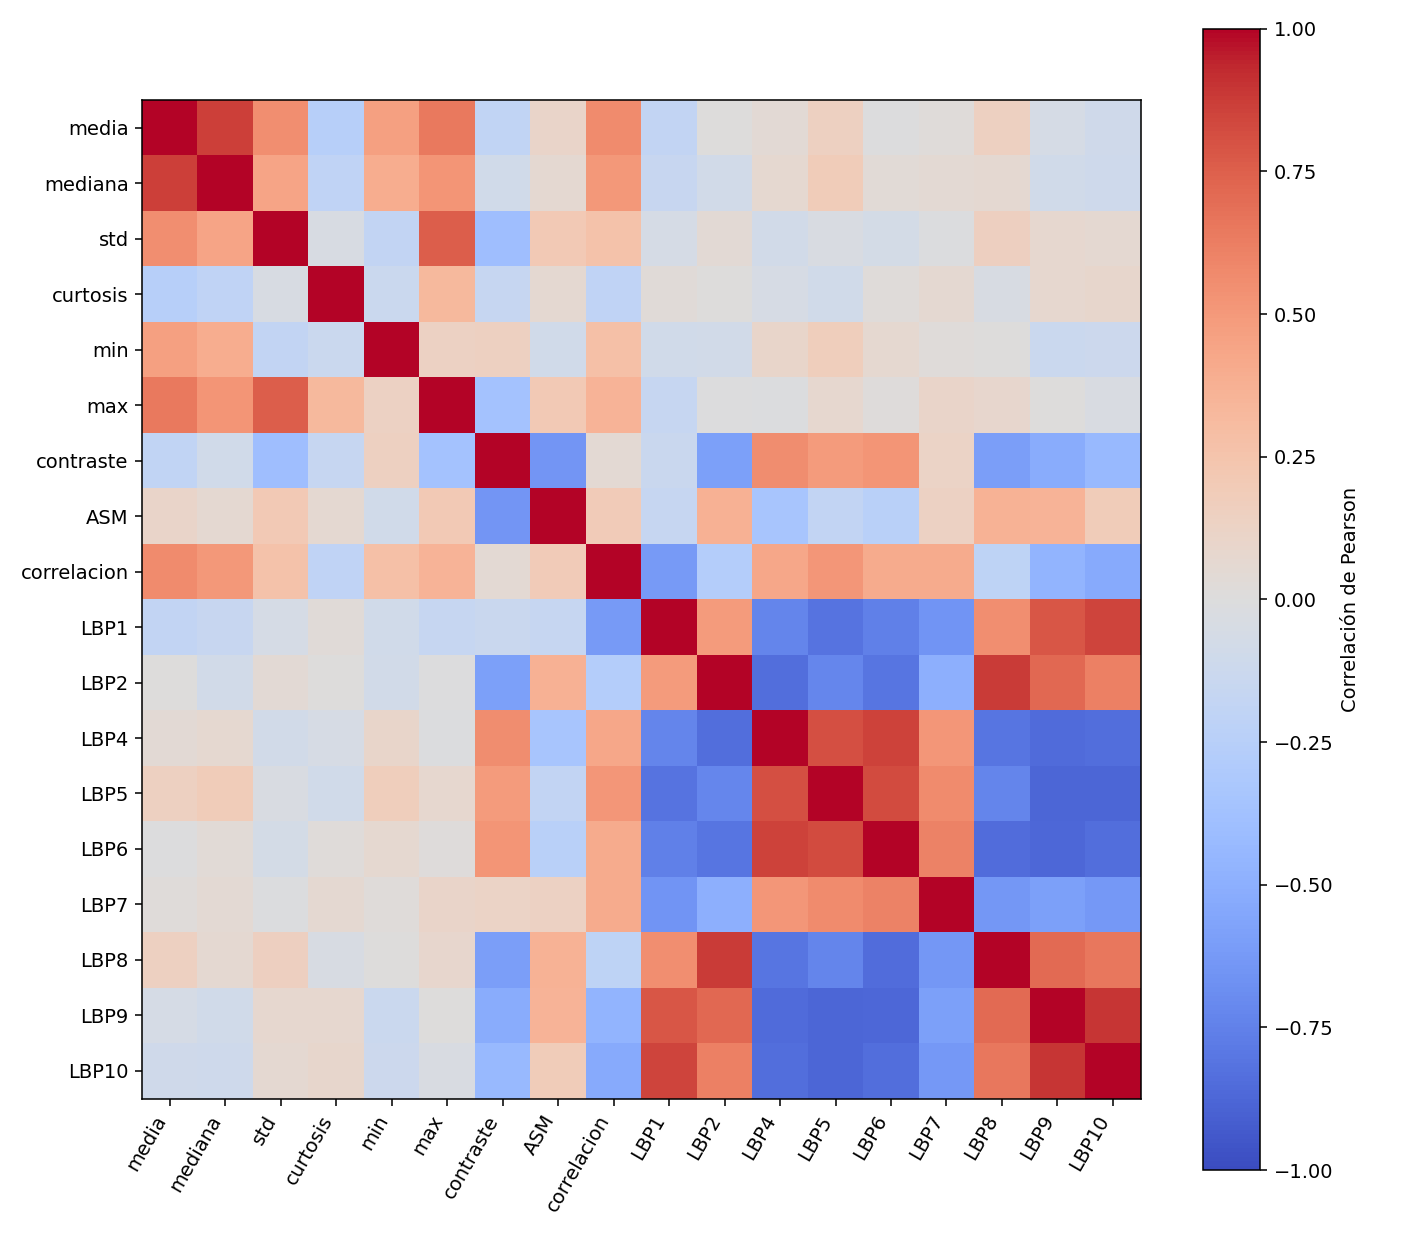

In [ ]:
selector, scaler = prepare_final_features(DATA_ROOT)
print("Índices seleccionados:", selector.selected_indices_)
print("Atributos seleccionados:", selector.get_feature_names_out(FEATURE_NAMES).tolist())
display(pd.read_csv(p["reports"] / "seleccion_caracteristicas.csv"))
display(Image(filename=str(p["reports"] / "04_correlacion_seleccionadas.png")))

### ¿Por qué se normaliza?

El valor de un atributo puede medirse en decenas de píxeles, mientras que otra característica es una frecuencia de 0 a 1. `StandardScaler` aplica `z=(x-media_train)/std_train` para que ninguna domine únicamente por su escala. Aquí mostramos las matrices finales **de apoyo didáctico**.

In [ ]:
arr_train = np.load(p["final"] / "train.npy")
arr_test = np.load(p["final"] / "test.npy")
print("Train final (variables elegidas + etiqueta):", arr_train.shape)
print("Test final  (variables elegidas + etiqueta):", arr_test.shape)
print("Primer vector normalizado:", arr_train[0])

Train final (variables elegidas + etiqueta): (151, 19)
Test final  (variables elegidas + etiqueta): (38, 19)
Primer vector normalizado: [ 0.33825926  0.1916417  -0.12296001 -0.71200444 -0.58399301 -0.7350668
  0.61530928 -0.75622115  0.04851546 -0.96100525  0.40195246  0.35071566
  0.99406674  0.62914019  1.67270171 -0.9519707  -0.87577903 -1.14358822
  0.        ]


## 5. Modelado: regresión logística frente a red MLP

**LOGR** es un clasificador lineal probabilístico. **MLP** es una red de capas densas (8 y 4 neuronas ocultas) con activación ReLU. En la validación cruzada de cinco folds se **reajustan selector y escalador dentro de cada fold**, para evitar fuga de información. Se guardan ambos pipelines entrenados sobre todo el train.

In [ ]:
models = train_models(DATA_ROOT)
display(pd.read_csv(p["reports"] / "05_validacion_cruzada.csv"))

LOGR: CV accuracy=0.8673 ± 0.0670 (5 folds)
MLP: CV accuracy=0.8409 ± 0.0578 (5 folds)


,modelo,accuracy_cv_media,accuracy_cv_desviacion,n_folds,n_caracteristicas
0,LOGR,0.867312,0.067001,5,18
1,MLP,0.840860,0.057773,5,18


## 6. Evaluación con test independiente

**Positivo = glaucoma (1).** Calculamos precisión, sensibilidad (recall), F1, accuracy y AUC-ROC usando `predict_proba`. La matriz de confusión tiene filas = clase real y columnas = predicción; orden `[healthy, glaucoma]`. NO se debe elegir un modelo basándose repetidamente en su test.


 LOGR 
               precision    recall  f1-score   support

     healthy       0.88      0.74      0.80        19
    glaucoma       0.77      0.89      0.83        19

    accuracy                           0.82        38
   macro avg       0.82      0.82      0.81        38
weighted avg       0.82      0.82      0.81        38

Matriz de confusión (filas reales, columnas predichas; healthy/glaucoma):
 [[14  5]
 [ 2 17]]

 MLP 
               precision    recall  f1-score   support

     healthy       0.82      0.74      0.78        19
    glaucoma       0.76      0.84      0.80        19

    accuracy                           0.79        38
   macro avg       0.79      0.79      0.79        38
weighted avg       0.79      0.79      0.79        38

Matriz de confusión (filas reales, columnas predichas; healthy/glaucoma):
 [[14  5]
 [ 3 16]]

Métricas finales en HOLD-OUT:
         precision  sensibilidad      f1  accuracy     auc
modelo                                             

,precision,sensibilidad,f1,accuracy,auc
modelo,,,,,
LOGR,0.772727,0.894737,0.829268,0.815789,0.831025
MLP,0.761905,0.842105,0.800000,0.789474,0.875346


Matriz de confusión: LOGR


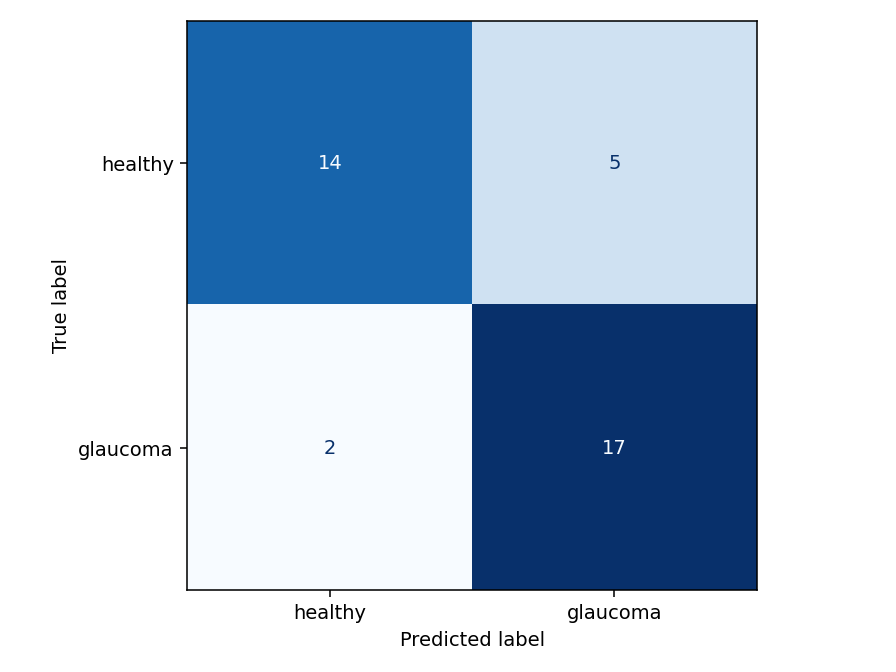

Matriz de confusión: MLP


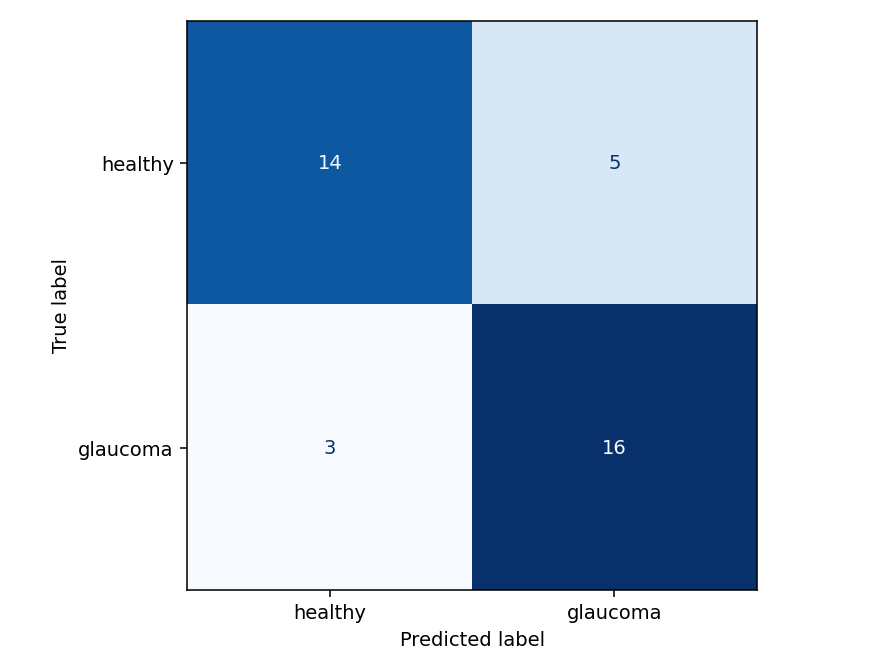

In [ ]:
resultados = evaluate(DATA_ROOT)
display(resultados)
for nombre in ("LOGR", "MLP"):
    print("Matriz de confusión:", nombre)
    display(Image(filename=str(p["reports"] / f"06_matriz_confusion_{nombre}.png")))

## Archivos obtenidos y límites

Mira `reports/` para CSV de resultados, probabilidades por imagen y gráficas; `models/` para el selector/escalador y cada pipeline serializado; `features/` y `final_features/` para las matrices. Los porcentajes capturados en la grabación pertenecen al conjunto de datos **no adjuntado** y no pueden darse por reproducidos. **Si activaste MODO_DEMO, todas las métricas son sintéticas y no tienen validez clínica.** Lee `docs/GUIA_DETALLADA.md` para comprender las operaciones paso por paso.

**ADVERTENCIA SYN-OCT:** La carpeta `Retina_masks` generada por `PREPARAR_SYN_OCT.py` es una **aproximación (ROI proxy)**, no una segmentación clínica de retina. Revise visualmente la RNFL; datos sintéticos solo para estudio, no diagnóstico.